# Task 1: Data Preprocessing

In [2]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

In [3]:
#1) Read the data from your individual variant into the Python notebook.
data = pd.read_excel("10_Student_Performance.xlsx", sheet_name='student-por.csv')

In [4]:
#2) Output the main information (number of variables, number of instances).
data.info()
print("Shape:",data.shape)

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    str  
 1   sex         649 non-null    str  
 2   age         649 non-null    int64
 3   address     649 non-null    str  
 4   famsize     649 non-null    str  
 5   Pstatus     649 non-null    str  
 6   Medu        649 non-null    int64
 7   Fedu        649 non-null    int64
 8   Mjob        649 non-null    str  
 9   Fjob        649 non-null    str  
 10  reason      649 non-null    str  
 11  guardian    649 non-null    str  
 12  traveltime  649 non-null    int64
 13  studytime   649 non-null    int64
 14  failures    649 non-null    int64
 15  schoolsup   649 non-null    str  
 16  famsup      649 non-null    str  
 17  paid        649 non-null    str  
 18  activities  649 non-null    str  
 19  nursery     649 non-null    str  
 20  higher      649 non-null    str  
 21  inte

In [5]:
#3) Output several first rows of the dataset.
data.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [6]:
#4) Make explanatory data analyses for each variable (mean, std, etc.).
data.describe(include='all')


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649,649,649.000000,649,649,649,649.000000,649.000000,649,649,...,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
unique,2,2,NaN,2,2,2,NaN,NaN,5,5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,GP,F,NaN,U,GT3,T,NaN,NaN,other,other,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,423,383,NaN,452,457,569,NaN,NaN,258,367,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,16.744222,NaN,NaN,NaN,2.514638,2.306626,NaN,NaN,...,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,NaN,NaN,1.218138,NaN,NaN,NaN,1.134552,1.099931,NaN,NaN,...,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,NaN,NaN,15.000000,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,NaN,NaN,16.000000,NaN,NaN,NaN,2.000000,1.000000,NaN,NaN,...,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,NaN,NaN,17.000000,NaN,NaN,NaN,2.000000,2.000000,NaN,NaN,...,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,NaN,NaN,18.000000,NaN,NaN,NaN,4.000000,3.000000,NaN,NaN,...,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000


In [7]:
#5) Look at the independent and dependent variables. Divide the dataset accordingly into matrices X and Y.
# Output the shapes of these matrices.
# => We will convert the 'G3' from a numerical to binary 'pass/fail' (pass when G3 >= 10 and fail when G3 < 10)

data['Class'] = np.where(data.G3 >= 10, 'Pass', 'Fail')
Y = data.Class
X = data.drop(['Class', 'G3'], axis=1)

print("X shape:", X.shape)
print("Y shape:", Y.shape)
print("Number of unique classes:", Y.nunique())
Y.value_counts()

X shape: (649, 32)
Y shape: (649,)
Number of unique classes: 2


Class
Pass    549
Fail    100
Name: count, dtype: int64

In [8]:
# 6) Look at data types of the variables. Are there any categorical variable you need to encode? Execute
# necessary transformations. Drop some columns if necessary, when recommended in your individual
# variant or the variables are not suitable for the prediction (e.g., Ids, person names).

# => we can easily encode the binary variables such as 'school', 'sex', 'adress' and so on, 
# and also the nominal variables, and we created 2 new variables from G1 and G2 that represent
# the average and the change between the two then we dropped them to avoid multicollinearity.

X['G_Avg'] = (X.G1 + X.G2) / 2
X['Grade_Change'] = X.G2 - X.G1
X = X.drop(['G1','G2'], axis=1)
le = LabelEncoder()
Y_encoded = le.fit_transform(Y)

X_encoded = pd.get_dummies(X,drop_first=True, dtype=int)
X_encoded.info()

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 41 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                649 non-null    int64  
 1   Medu               649 non-null    int64  
 2   Fedu               649 non-null    int64  
 3   traveltime         649 non-null    int64  
 4   studytime          649 non-null    int64  
 5   failures           649 non-null    int64  
 6   famrel             649 non-null    int64  
 7   freetime           649 non-null    int64  
 8   goout              649 non-null    int64  
 9   Dalc               649 non-null    int64  
 10  Walc               649 non-null    int64  
 11  health             649 non-null    int64  
 12  absences           649 non-null    int64  
 13  G_Avg              649 non-null    float64
 14  Grade_Change       649 non-null    int64  
 15  school_MS          649 non-null    int64  
 16  sex_M              649 non-null    in

In [9]:
# 7) Are there any Nan values? Try different filling of them (mean, median).
nan_count = X_encoded.isnull().sum().sum()
print("Total NaN valus in dataset :", nan_count)

X_filled_mean = X_encoded.fillna(X_encoded.mean(numeric_only=True))
X_filled_median = X_encoded.fillna(X_encoded.median(numeric_only=True))
print("Shapes after mean/median imputation:", X_filled_mean.shape, X_filled_median.shape)


Total NaN valus in dataset : 0
Shapes after mean/median imputation: (649, 41) (649, 41)


In [10]:
# The dataset contains 0 missing (NaN) values, so mean and median imputation leave the data unchanged.

Target_Class         1.000000
G_Avg                0.598636
higher_yes           0.309708
studytime            0.165111
Fedu                 0.146249
Medu                 0.144803
address_U            0.126663
reason_reputation    0.123914
Grade_Change         0.121566
Mjob_teacher         0.096404
internet_yes         0.088215
reason_home          0.060466
famsize_LE3          0.052215
Fjob_teacher         0.047490
activities_yes       0.047276
famrel               0.044987
famsup_yes           0.037903
schoolsup_yes        0.034527
Mjob_health          0.022766
Fjob_other           0.021943
Mjob_services        0.020504
Fjob_health          0.012556
Pstatus_T           -0.004241
nursery_yes         -0.007751
health              -0.009979
Mjob_other          -0.019592
guardian_mother     -0.045609
guardian_other      -0.047062
Fjob_services       -0.048640
paid_yes            -0.053708
traveltime          -0.057869
goout               -0.067241
sex_M               -0.078222
romantic_y

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,guardian_other,schoolsup_yes,famsup_yes,paid_yes,activities_yes,nursery_yes,higher_yes,internet_yes,romantic_yes,Target_Class
age,1.000000,-0.107832,-0.121050,0.034490,-0.008415,0.319968,-0.020559,-0.004910,0.112805,0.134768,...,0.330353,-0.167841,-0.101894,-0.005458,-0.054279,-0.021441,-0.265497,0.013115,0.178810,-0.110722
Medu,-0.107832,1.000000,0.647477,-0.265079,0.097006,-0.172210,0.024421,-0.019686,0.009536,-0.007018,...,-0.101123,-0.022168,0.120491,0.113973,0.119354,0.125951,0.213896,0.266052,-0.030992,0.144803
Fedu,-0.121050,0.647477,1.000000,-0.208288,0.050400,-0.165915,0.020256,0.006841,0.027690,0.000061,...,-0.066684,0.023572,0.135191,0.094628,0.079700,0.074863,0.191735,0.183483,-0.067675,0.146249
traveltime,0.034490,-0.265079,-0.208288,1.000000,-0.063154,0.097730,-0.009521,0.000937,0.057454,0.092824,...,0.090497,-0.044807,-0.039289,-0.044842,-0.033376,-0.011509,-0.071958,-0.190826,0.004751,-0.057869
studytime,-0.008415,0.097006,0.050400,-0.063154,1.000000,-0.147441,-0.004127,-0.068829,-0.075442,-0.137585,...,0.006440,0.089316,0.143509,-0.002314,0.070080,0.042630,0.188256,0.037529,0.033036,0.165111
failures,0.319968,-0.172210,-0.165915,0.097730,-0.147441,1.000000,-0.062645,0.108995,0.045078,0.105949,...,0.234027,-0.000745,-0.006982,0.069416,0.000561,-0.069241,-0.309400,-0.095330,0.069901,-0.380237
famrel,-0.020559,0.024421,0.020256,-0.009521,-0.004127,-0.062645,1.000000,0.129216,0.089707,-0.075767,...,-0.067365,-0.012038,0.015228,0.031937,0.057597,0.041055,0.048239,0.082214,-0.044920,0.044987
freetime,-0.004910,-0.019686,0.006841,0.000937,-0.068829,0.108995,0.129216,1.000000,0.346352,0.109904,...,0.033823,-0.015611,0.003764,-0.049574,0.150329,-0.007096,-0.102618,0.063268,0.027112,-0.093349
goout,0.112805,0.009536,0.027690,0.057454,-0.075442,0.045078,0.089707,0.346352,1.000000,0.245126,...,0.018432,-0.058124,0.017262,-0.006683,0.088582,0.018679,-0.069105,0.092869,-0.000520,-0.067241
Dalc,0.134768,-0.007018,0.000061,0.092824,-0.137585,0.105949,-0.075767,0.109904,0.245126,1.000000,...,0.112437,-0.028076,-0.016844,0.051986,0.022592,-0.078376,-0.131663,0.042811,0.062042,-0.123627


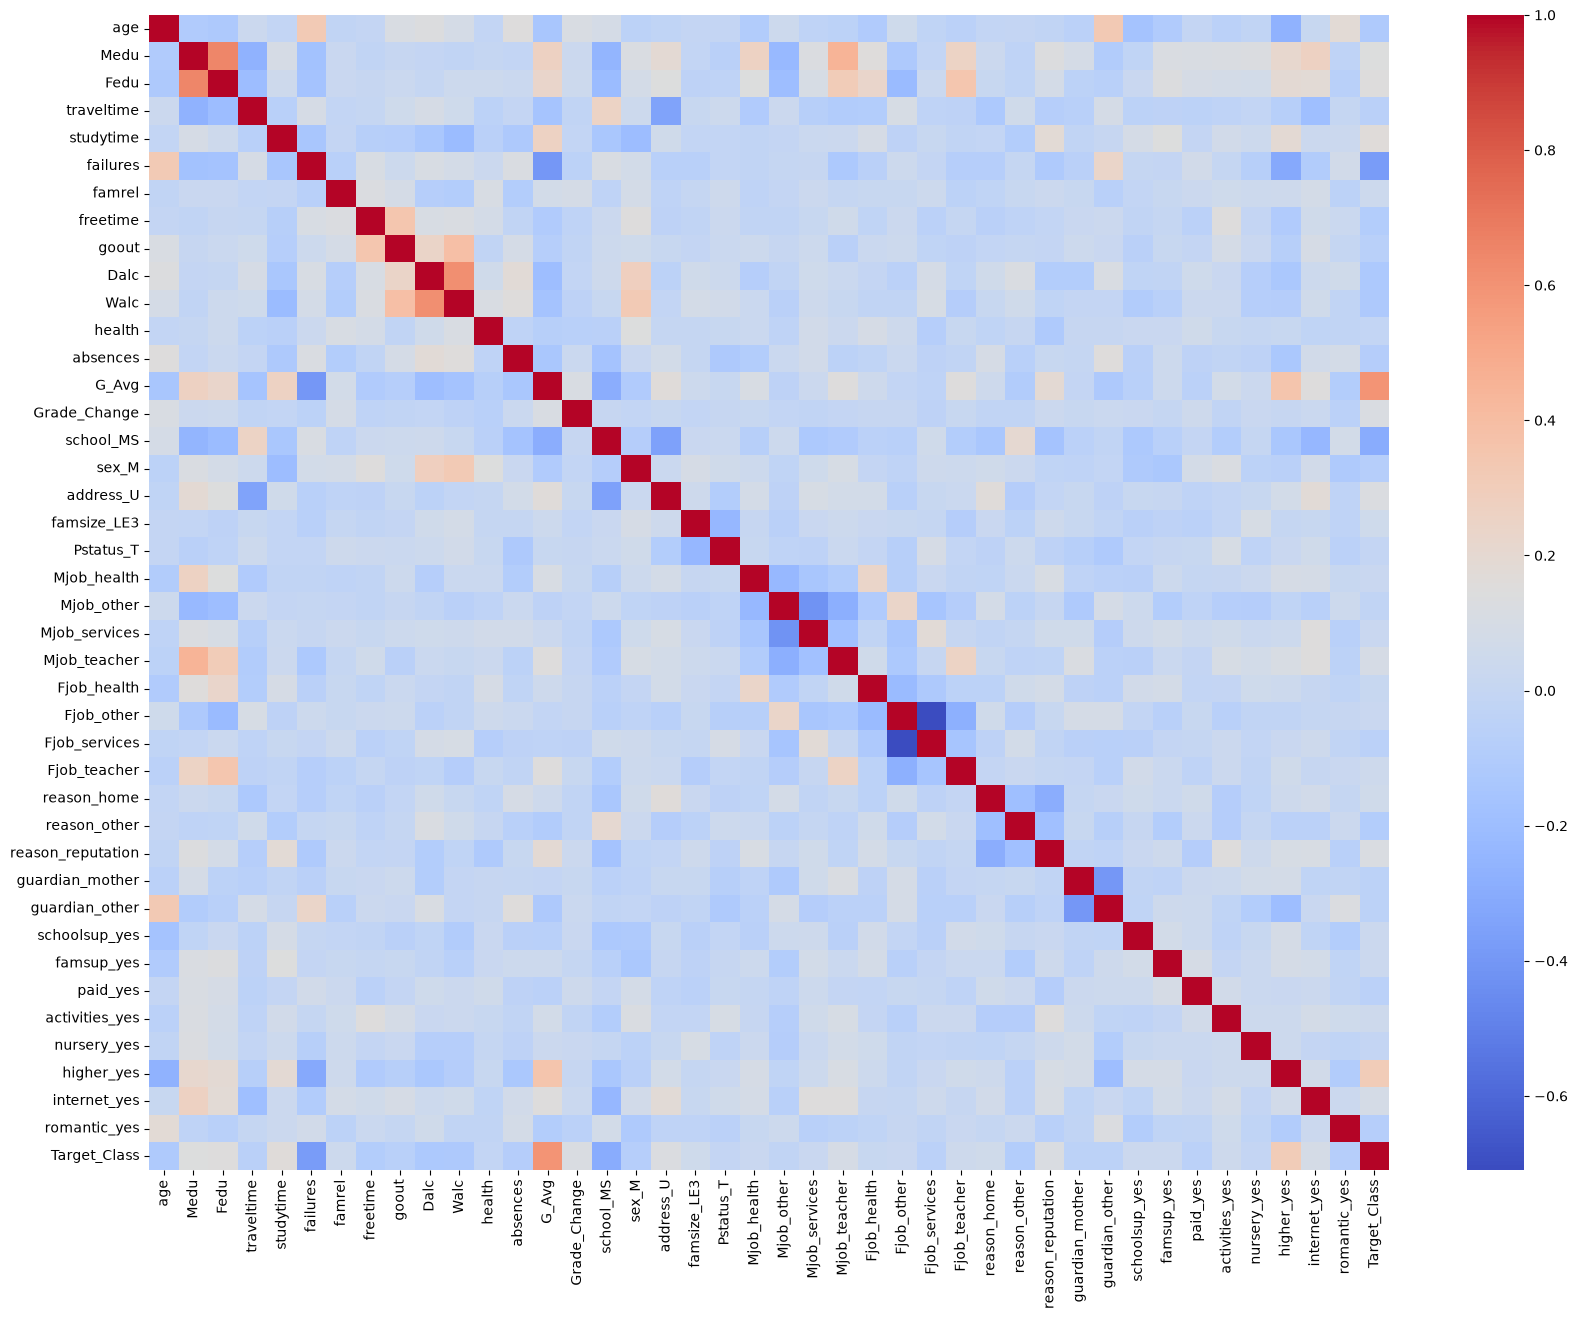

In [11]:
# 8) Check the dependences between each of the independent variable and the target variable and among
# the independent variables. Output correlation table and corresponding heatmap results.

corr_data = X_encoded.copy()
corr_data['Target_Class'] = Y_encoded

corr_table = corr_data.corr()
display(corr_table['Target_Class'].sort_values(ascending=False))
display(corr_table)
plt.figure(figsize=(20, 15))
sns.heatmap(corr_table, annot=False, cmap='coolwarm')
plt.show()

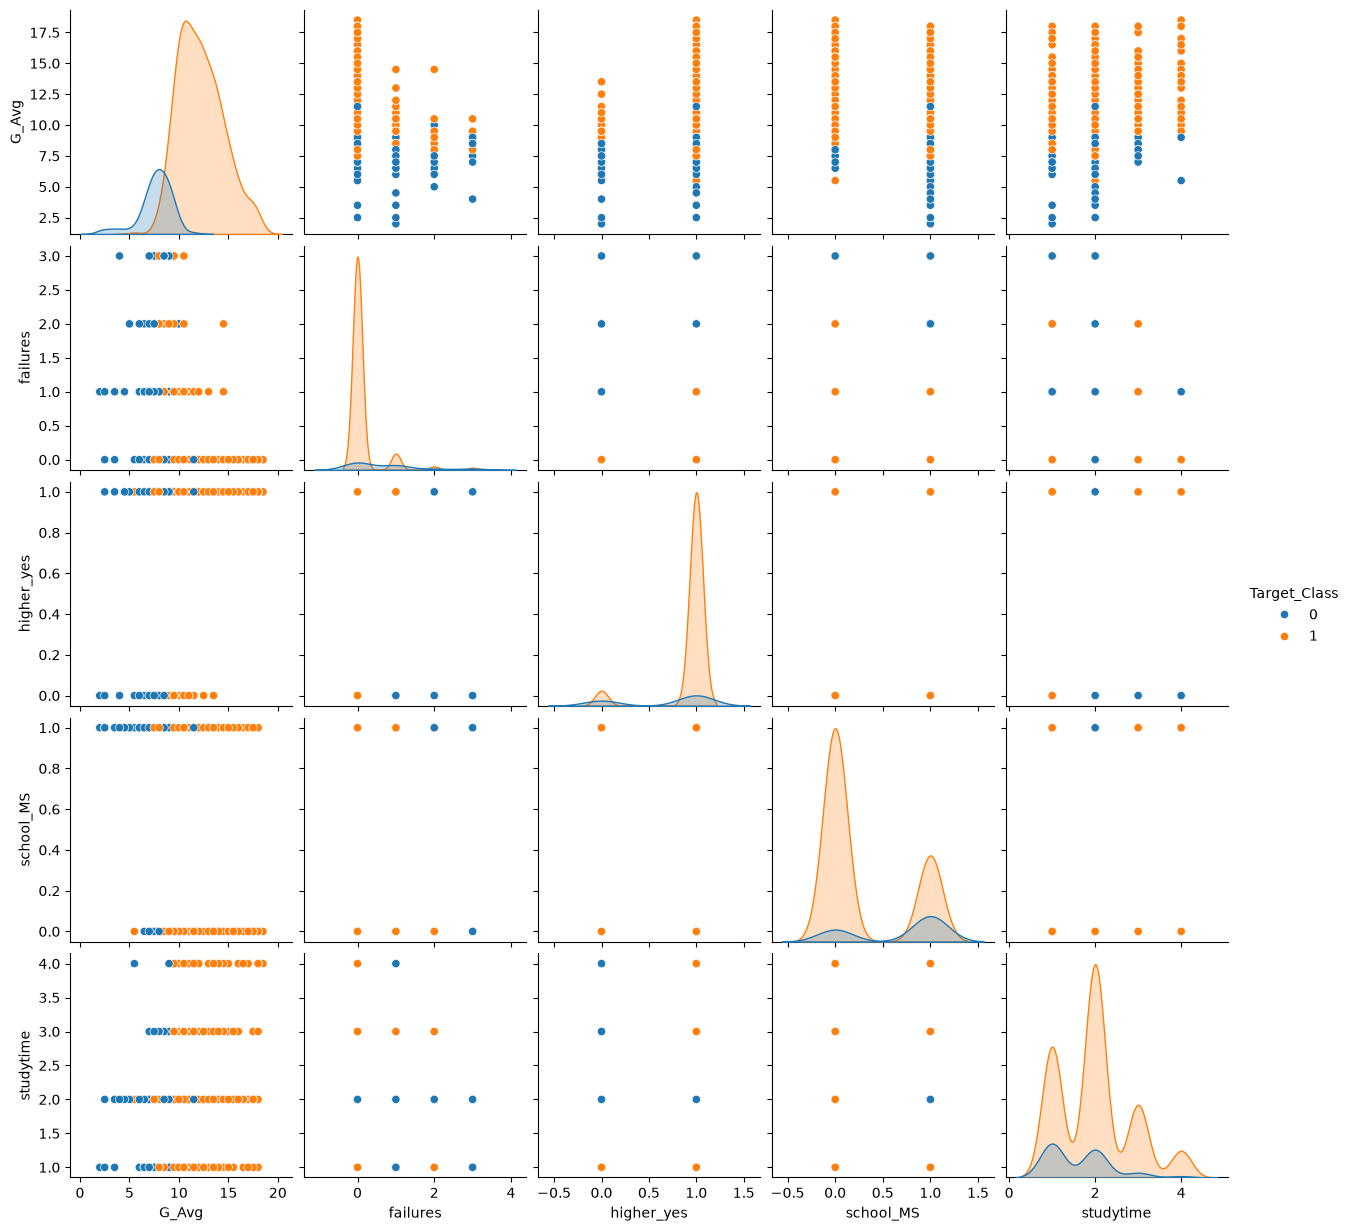

In [12]:
#9) Build 2D plots of dependences between each pair of the variables. Which conclusion can you make?
list_variables = corr_table['Target_Class'].abs().nlargest(6).index
sns.pairplot(corr_data[list_variables], hue='Target_Class')
plt.show()

In [13]:
# Conclusions : 
# - G_Avg is the strongest separator between classes, with failing students (class 0) concentrated 
# below 10 and passing students (class 1) above 10.
# - Students with higher studytime and plans for higher education (higher_yes = 1) achieve higher 
# G_Avg scores and predominantly pass, while students with multiple past failures cluster at lower G_Avg values and fail.

# Task 2: Data Analysis

In [14]:
# 1) Divide your dataset into 2 parts: training set and testing set (80:20). Use some specific random_state to
# be capable to repeat the used split of the data. Output the dimension of the resulting datasets.

X_train, X_test, Y_train, Y_test = train_test_split(
    X_encoded, Y_encoded, test_size=0.2, random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("Y_train shape:", Y_train.shape)
print("Y_test shape:", Y_test.shape)


X_train shape: (519, 41)
X_test shape: (130, 41)
Y_train shape: (519,)
Y_test shape: (130,)


In [15]:
# 2) Scale your datasets with MinMax Scaler.

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

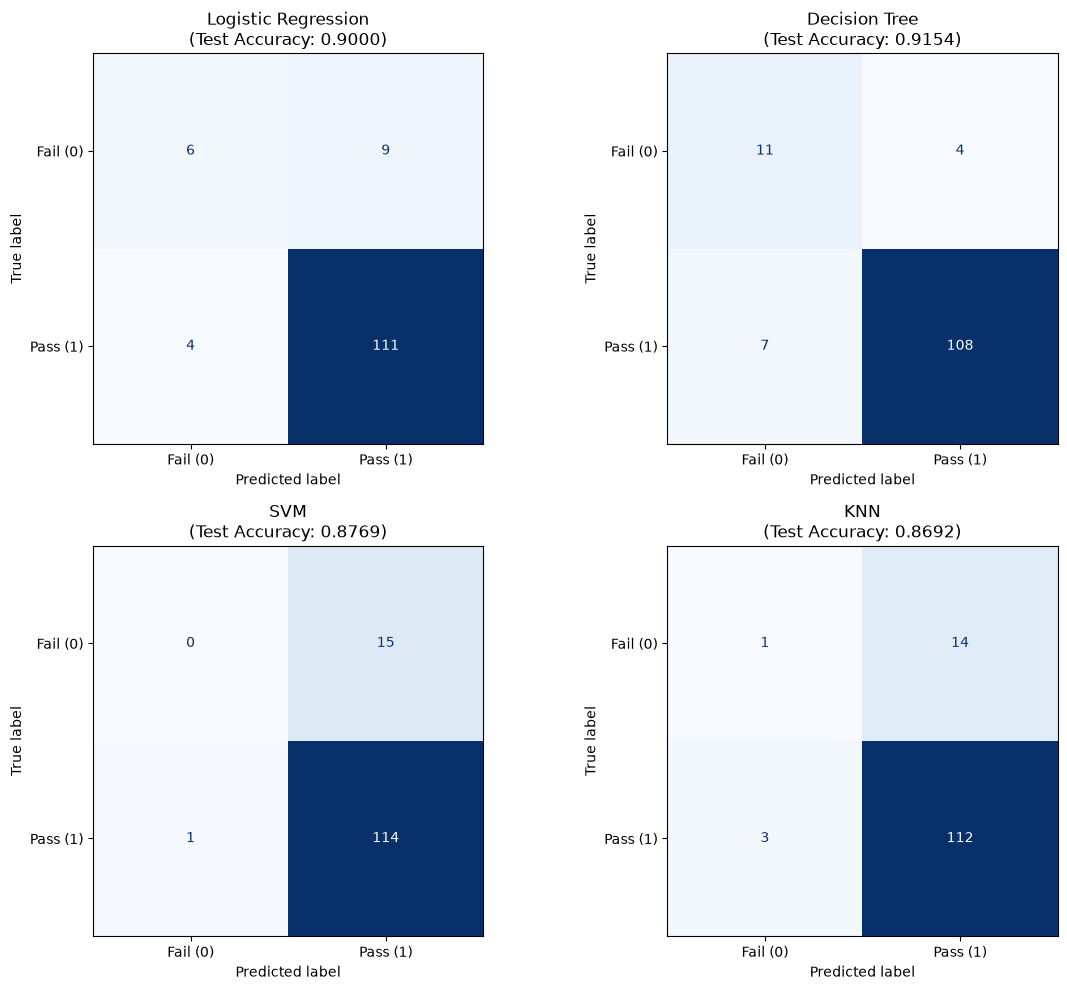

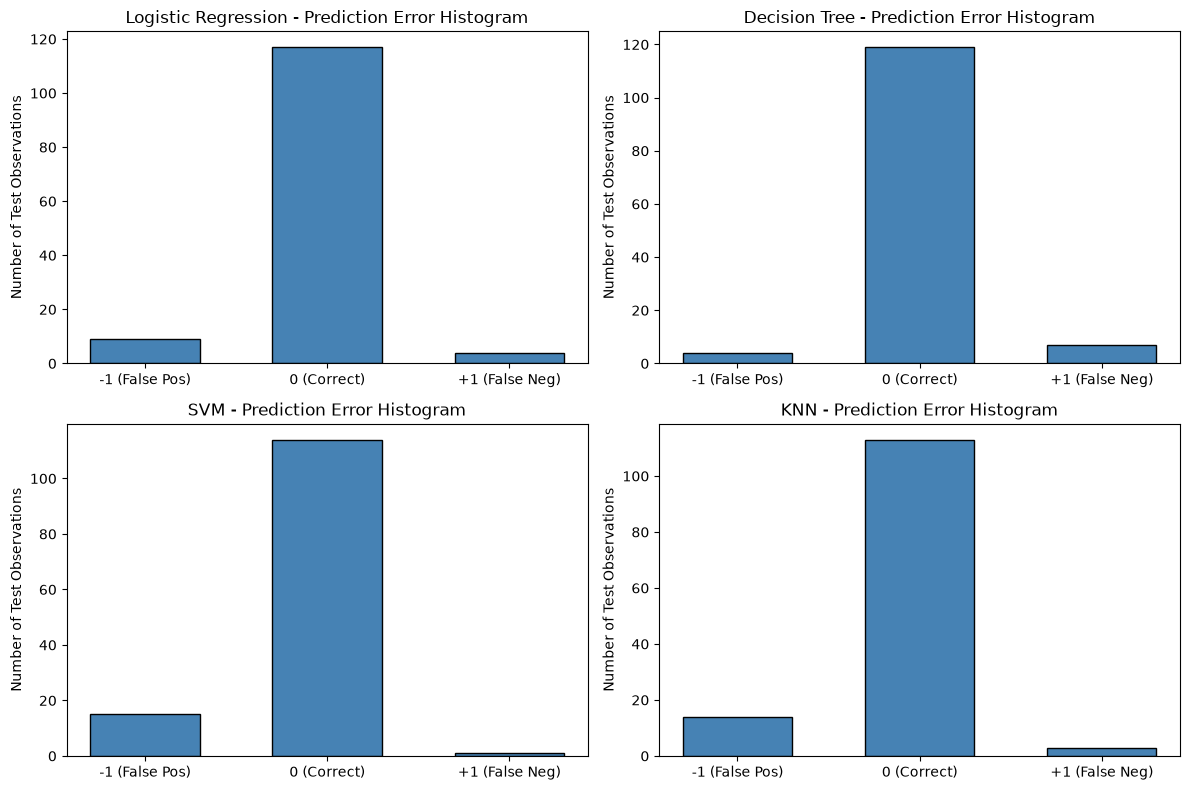

,Train Accuracy,Test Accuracy
Logistic Regression,0.897881,0.900000
Decision Tree,1.000000,0.915385
SVM,0.890173,0.876923
KNN,0.853565,0.869231


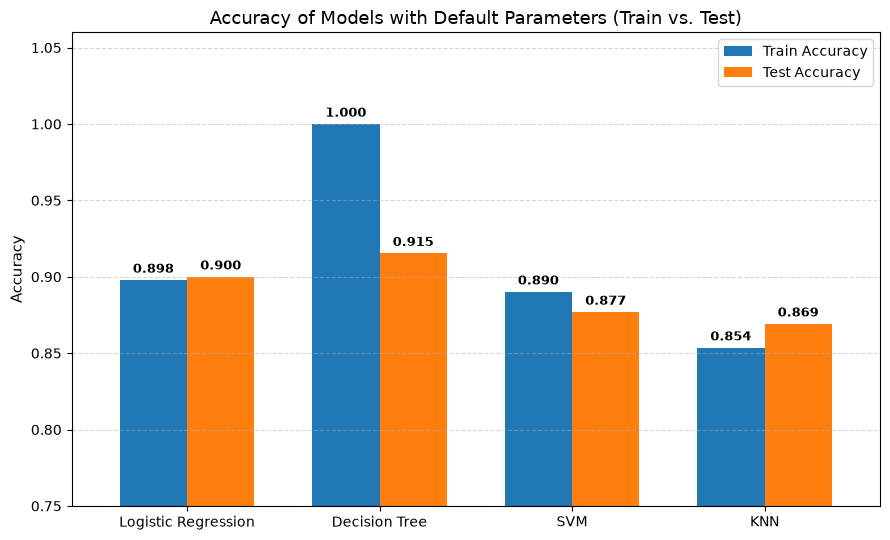

In [35]:
# 3) Preliminary analysis: Build 4 models based on 4 mentioned ML methods with default parameters. For
# each model: train with training set and output the regression score (R2), MSE, MAE of the model using
# training set. Now test your model with a testset and output the regression score (R2) and other metrics.
# Compare the metrics obtained with training and testset. Output dataframes with the following
# information. One dataframe for each metrics (e.g. 3 dataframes). Each row of the dataframe should
# correspond to a model and two columns correspond to the metric calculated on the training set and on
# the testset. Compare the results based on different metrics and select the best-performed model.
# Construct prediction squared errors histograms for each of the models, construct parity plots of each
# model.

models = {'Logistic Regression': LogisticRegression(), 
          'Decision Tree': DecisionTreeClassifier(random_state=42),
          'SVM': SVC(),
          'KNN': KNeighborsClassifier()}

accuracy_results = {}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):
    model.fit(X_train_scaled, Y_train)

    train_pred = model.predict(X_train_scaled)
    test_pred = model.predict(X_test_scaled)

    train_acc = accuracy_score(Y_train, train_pred)
    test_acc = accuracy_score(Y_test, test_pred)

    accuracy_results[name] = {
        'Train Accuracy': train_acc,
        'Test Accuracy': test_acc
    }

    cm = confusion_matrix(Y_test, test_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Fail (0)', 'Pass (1)'])
    disp.plot(ax=axes[i], cmap='Blues', colorbar=False)
    axes[i].set_title(f"{name}\n(Test Accuracy: {test_acc:.4f})")

plt.tight_layout()
plt.show()

# Construct prediction errors histograms for each of the models
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):
    test_pred = model.predict(X_test_scaled)
    errors = Y_test - test_pred  # 0 = Correct, -1 = False Positive, +1 = False Negative
    axes[i].hist(errors, bins=[-1.5, -0.5, 0.5, 1.5], rwidth=0.6, color='steelblue', edgecolor='black')
    axes[i].set_xticks([-1, 0, 1])
    axes[i].set_xticklabels(['-1 (False Pos)', '0 (Correct)', '+1 (False Neg)'])
    axes[i].set_title(f"{name} - Prediction Error Histogram")
    axes[i].set_ylabel("Number of Test Observations")

plt.tight_layout()
plt.show()


# Output DataFrame: rows = models, 2 columns = Train Accuracy and Test Accuracy
accuracy_df = pd.DataFrame(accuracy_results).T
display(accuracy_df)

#display(accuracy_df.plot(kind='bar', ylim=(0.75, 1.05), rot=0))

#------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5.5))
accuracy_df.plot(kind='bar', ax=ax, rot=0, width=0.7)

ax.set_title('Accuracy of Models with Default Parameters (Train vs. Test)', fontsize=13)
ax.set_ylabel('Accuracy', fontsize=11)
ax.set_ylim(0.75, 1.06)
ax.grid(axis='y', linestyle='--', alpha=0.5)

for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3, fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.show()




In [17]:
# Decision Tree has the best score, it reaches 100% training accuracy and 91.54% test accuracy, but 
# the most stable is the logistic regression model, from 89.79% on training accuracy to 90% on test accuracy.
# Meanwhile both SVM and KNN scored poorly compared to the other models.

Logistic Regression -> Optimal Parameters: {'C': 100} (CV Accuracy: 0.9171)
Decision Tree -> Optimal Parameters: {'max_depth': 3, 'min_samples_split': 2} (CV Accuracy: 0.9305)
SVM -> Optimal Parameters: {'C': 100, 'kernel': 'linear'} (CV Accuracy: 0.9171)
KNN -> Optimal Parameters: {'n_neighbors': 11, 'weights': 'distance'} (CV Accuracy: 0.8401)


,Variable,Coefficient
13,G_Avg,35.357645
14,Grade_Change,3.492522
0,age,3.348407
30,reason_reputation,0.896124
10,Walc,0.848660
23,Mjob_teacher,0.753644
38,higher_yes,0.500707
33,schoolsup_yes,0.365324
28,reason_home,0.286638
29,reason_other,0.282653


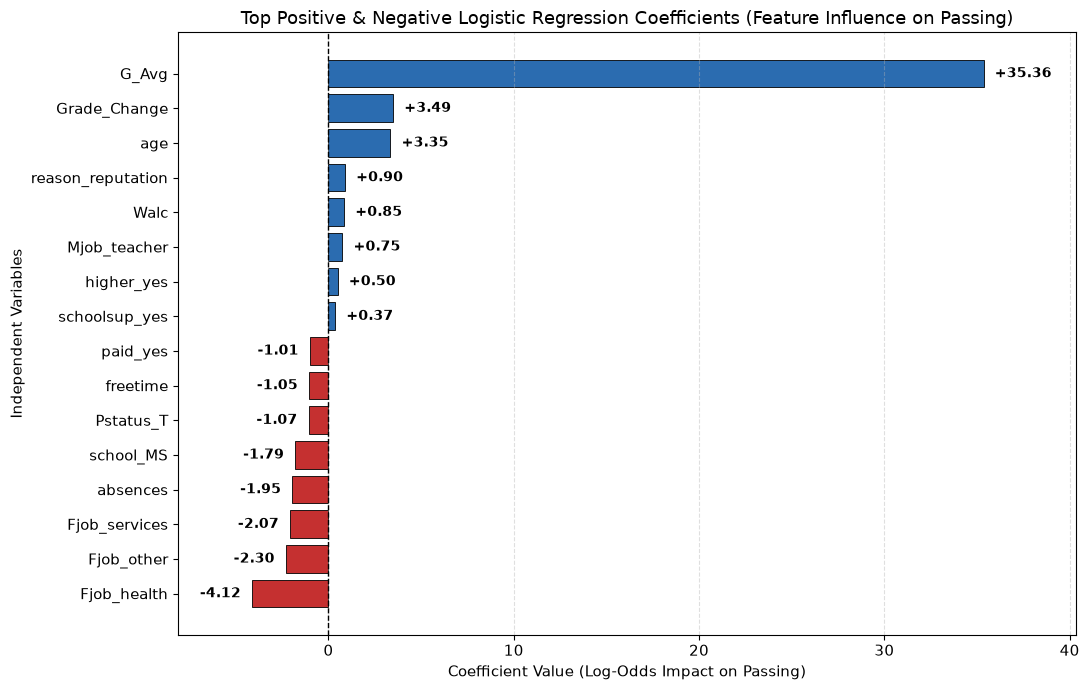

In [36]:
# 4) Find optimal parameters of the above created models with GridSearchCV() function based on the
# training dataset. Output the optimal values of parameters found for each model. Output and construct
# bar plots of the coefficients of the linear regression model. Which variables have the biggest influence
# on the output (dependent variables)?

from sklearn.model_selection import GridSearchCV

base_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'SVM': SVC(),
    'KNN': KNeighborsClassifier()
}

param_grids = {
    'Logistic Regression': {'C': [0.01, 0.1, 1, 10, 100]},
    'Decision Tree': {'max_depth': [2, 3, 4, 5, 7, 10], 'min_samples_split': [2, 5, 10]},
    'SVM': {'C': [0.1, 1, 10, 100], 'kernel': ['linear', 'rbf']},
    'KNN': {'n_neighbors': [3, 5, 7, 9, 11], 'weights': ['uniform', 'distance']}
}

best_models = {}

for name, model in base_models.items():
    grid = GridSearchCV(estimator=model, param_grid=param_grids[name], cv=5, scoring='accuracy')
    grid.fit(X_train_scaled, Y_train)
    
    best_models[name] = grid.best_estimator_
    print(f"{name} -> Optimal Parameters: {grid.best_params_} (CV Accuracy: {grid.best_score_:.4f})")

best_log_reg = best_models['Logistic Regression']
coef_df = pd.DataFrame({
    'Variable': X_encoded.columns,
    'Coefficient': best_log_reg.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

display(coef_df)

# plt.figure(figsize=(12, 10))
# sns.barplot(data=coef_df, x='Coefficient', y='Variable', palette='coolwarm')
# plt.axvline(0, color='black', linestyle='--', linewidth=1)
# plt.title('Logistic Regression Coefficients (Feature Influence on Passing)')
# plt.xlabel('Coefficient Value')
# plt.ylabel('Independent Variables')
# plt.tight_layout()
# plt.show()

#------------------------------------------------------------

top_coef_df = pd.concat([coef_df.head(8), coef_df.tail(8)]).sort_values(by='Coefficient', ascending=False)
bar_colors = ['#2b6cb0' if val > 0 else '#c53030' for val in top_coef_df['Coefficient']]

fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(
    top_coef_df['Variable'],
    top_coef_df['Coefficient'],
    color=bar_colors,
    edgecolor='black',
    linewidth=0.6
)

ax.invert_yaxis()
ax.axvline(0, color='black', linestyle='--', linewidth=1)
ax.grid(axis='x', linestyle='--', alpha=0.4)

for bar in bars:
    val = bar.get_width()
    offset = 0.6 if val >= 0 else -0.6
    ha = 'left' if val >= 0 else 'right'
    ax.text(
        val + offset,
        bar.get_y() + bar.get_height() / 2,
        f'{val:+.2f}',
        va='center',
        ha=ha,
        fontsize=10,
        fontweight='bold'
    )

ax.set_xlim(top_coef_df['Coefficient'].min() - 4, top_coef_df['Coefficient'].max() + 5)
ax.set_title('Top Positive & Negative Logistic Regression Coefficients (Feature Influence on Passing)', fontsize=13)
ax.set_xlabel('Coefficient Value (Log-Odds Impact on Passing)', fontsize=11)
ax.set_ylabel('Independent Variables', fontsize=11)
ax.tick_params(axis='both', labelsize=10.5)

plt.tight_layout()
plt.show()



In [19]:
# - G_Avg (+35.36), Grade_Change (+3.49), and age (+3.35) have the strongest positive influence on passing.
# - Fjob_health (-4.12), Fjob_other (-2.30), Fjob_services (-2.07), and absences (-1.95) have the strongest negative influence.

,Train Accuracy,Test Accuracy,Optimized Train,Optimized Test
Logistic Regression,0.897881,0.900000,0.949904,0.907692
Decision Tree,1.000000,0.915385,0.949904,0.907692
SVM,0.890173,0.876923,0.961464,0.915385
KNN,0.853565,0.869231,1.000000,0.884615


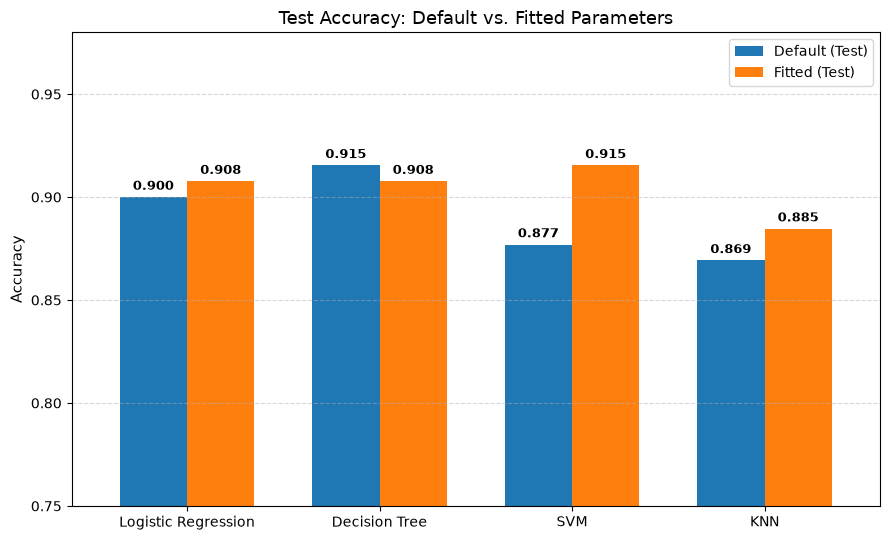

In [37]:
# 5) Evaluate the performance of the models with optimal values of the parameters. Output the results in
# the similar dataframe as in Task 2.3. Compare the results with obtained in Task 2.3. Make the conclusion
# about the best-fitted model before and after optimization of the parameters.

optimized_results = {}

for name, model in best_models.items():
    train_pred = model.predict(X_train_scaled)
    test_pred = model.predict(X_test_scaled)
    
    optimized_results[name] = {
        'Optimized Train': accuracy_score(Y_train, train_pred),
        'Optimized Test': accuracy_score(Y_test, test_pred)
    }

optimized_df = pd.DataFrame(optimized_results).T
comparison_df = pd.concat([accuracy_df, optimized_df], axis=1)
display(comparison_df)

#display(comparison_df[['Test Accuracy', 'Optimized Test']].plot(kind='bar', ylim=(0.75, 0.98), rot=0))

#------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5.5))
plot_df = comparison_df[['Test Accuracy', 'Optimized Test']].rename(
    columns={'Test Accuracy': 'Default (Test)', 'Optimized Test': 'Fitted (Test)'}
)
plot_df.plot(kind='bar', ax=ax, rot=0, width=0.7)

ax.set_title('Test Accuracy: Default vs. Fitted Parameters', fontsize=13)
ax.set_ylabel('Accuracy', fontsize=11)
ax.set_ylim(0.75, 0.98)
ax.grid(axis='y', linestyle='--', alpha=0.5)

for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3, fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.show()



In [21]:
# Before hyperparameter tuning, the default Decision Tree achieved the highest test accuracy but 
# suffered from severe overfitting by memorizing the training data. After optimization with 
# cross-validation, Support Vector Machine with a linear kernel became the best-performing model 
# on the unseen test set, while pruning the Decision Tree and tuning Logistic Regression reduced 
# overfitting and produced reliable runners-up.

,Real Values,Logistic Regression,Decision Tree,SVM,KNN
636,1,1,1,1,1
220,1,1,1,1,1
594,1,1,1,1,1
429,1,1,1,1,1
72,1,1,1,1,1
448,1,1,1,1,1
181,1,1,1,1,1
131,0,1,1,1,1
231,1,1,1,1,1
277,1,1,1,1,1


,Real Values,Logistic Regression,Decision Tree,SVM,KNN
327,1,1,1,1,1
165,1,1,1,1,1
10,1,1,1,1,1
55,1,1,1,1,1
352,1,1,1,1,1
176,1,0,0,0,1
493,1,1,0,1,1
318,1,1,1,1,1
607,1,1,1,1,1
177,0,1,0,0,1


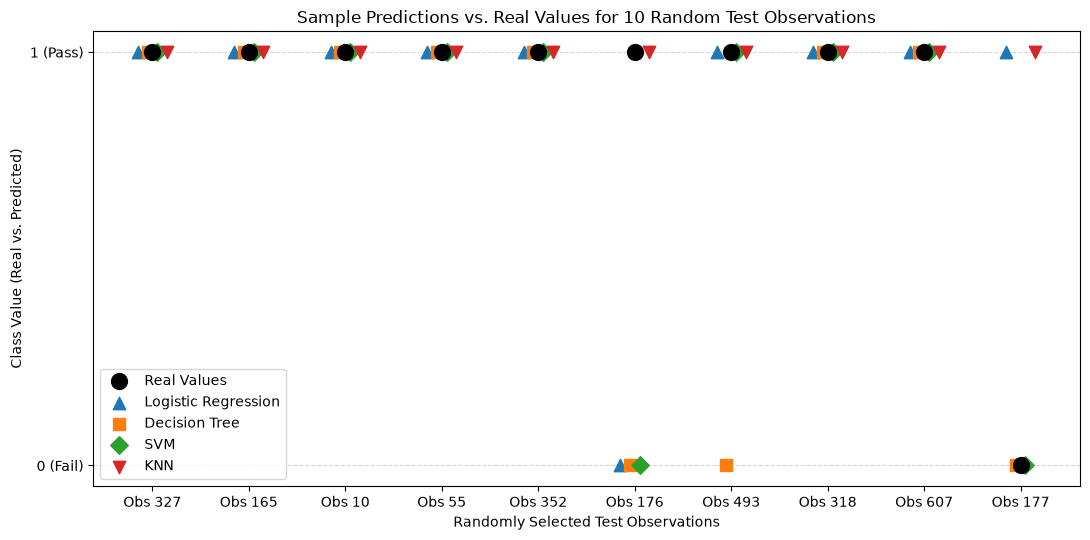

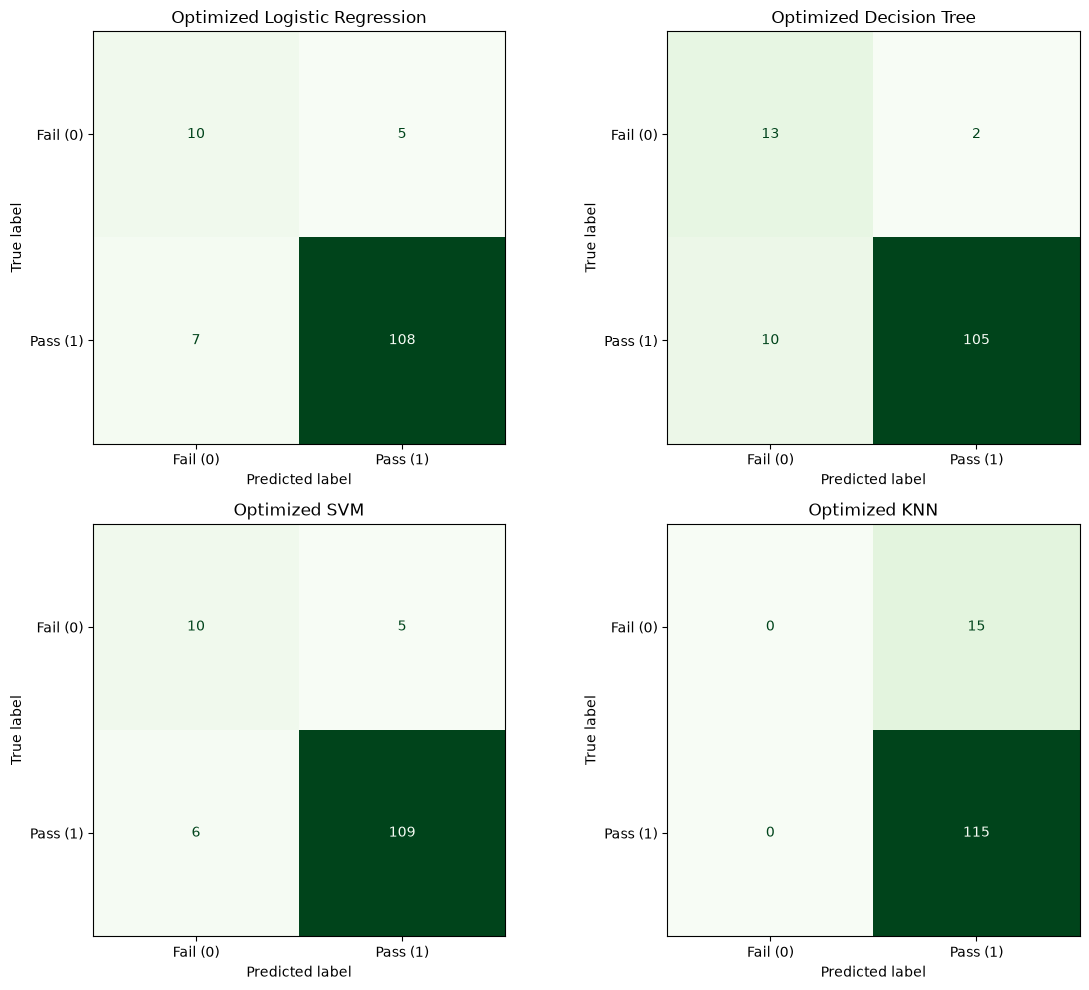

In [22]:
# 6) Output the prediction results of the models with optimal parameters: create a dataframe with 5
# columns, which correspond to "real values" and predicted values by each model on the testset and rows
# correspond to the observations from the testset. Construct a plot, which illustrates sample predictions
# for each model for randomly selected 10 observations from the testset (X-axis: observations, Y-axis:
# predicted value) and compare them to the real values. Output confusion matrix for each of the models.

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

predictions_df = pd.DataFrame({'Real Values': Y_test}, index=X_test.index)
for name, model in best_models.items():
    predictions_df[name] = model.predict(X_test_scaled)

display(predictions_df.head(10))

sample_10 = predictions_df.sample(n=10, random_state=42)
display(sample_10)

plt.figure(figsize=(11, 5.5))
x_pos = np.arange(len(sample_10))
x_labels = [f"Obs {idx}" for idx in sample_10.index]

plt.scatter(x_pos, sample_10['Real Values'], color='black', marker='o', s=130, label='Real Values', zorder=5)
offsets = [-0.15, -0.05, 0.05, 0.15]
markers = ['^', 's', 'D', 'v']

for i, name in enumerate(best_models.keys()):
    plt.scatter(x_pos + offsets[i], sample_10[name], marker=markers[i], s=80, label=name, zorder=4)

plt.xticks(x_pos, x_labels)
plt.yticks([0, 1], ['0 (Fail)', '1 (Pass)'])
plt.xlabel('Randomly Selected Test Observations')
plt.ylabel('Class Value (Real vs. Predicted)')
plt.title('Sample Predictions vs. Real Values for 10 Random Test Observations')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(best_models.items()):
    cm = confusion_matrix(Y_test, predictions_df[name])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Fail (0)', 'Pass (1)'])
    disp.plot(ax=axes[i], cmap='Greens', colorbar=False)
    axes[i].set_title(f"Optimized {name}")

plt.tight_layout()
plt.show()


In [23]:
# 7) Calculate the prediction errors of each observation from the testset and obtained by each model. Make
# conclusions about the predictions, which have the biggest prediction error. Compare the prediction
# errors. Are there any observations badly predicted by all the methods?

errors_df = pd.DataFrame(index=X_test.index)
for name in best_models.keys():
    errors_df[name] = (predictions_df[name] != predictions_df['Real Values']).astype(int)

errors_df['Total_Models_Wrong'] = errors_df.sum(axis=1)

print("Misclassified observations per model:")
print(errors_df.sum())

print("\nBreakdown of observations by number of models wrong:")
print(errors_df['Total_Models_Wrong'].value_counts().sort_index())

# Filter observations wrongly classified by all 4 models
all_wrong_idx = errors_df[errors_df['Total_Models_Wrong'] == 4].index
all_wrong_details = pd.concat([
    predictions_df.loc[all_wrong_idx],
    data.loc[all_wrong_idx, ['G1', 'G2', 'G3', 'failures', 'absences']]
], axis=1)

print("\nObservations wrongly classified by all models:")
display(all_wrong_details)


Misclassified observations per model:
Logistic Regression    12
Decision Tree          12
SVM                    11
KNN                    15
Total_Models_Wrong     50
dtype: int64

Breakdown of observations by number of models wrong:
Total_Models_Wrong
0    104
1     13
2      4
3      7
4      2
Name: count, dtype: int64

Observations wrongly classified by all models:


,Real Values,Logistic Regression,Decision Tree,SVM,KNN,G1,G2,G3,failures,absences
131,0,1,1,1,1,10,9,8,3,10
163,0,1,1,1,1,11,9,0,2,0


In [24]:
# SVM produced the fewest classification errors on the test set, Logistic Regression 
# and Decision Tree tied for second, and KNN made the most mistakes because it predicted 
# every student would pass. Only two borderline students were misclassified by all four 
# models, as both had prior trimester grades near the passing cutoff before experiencing 
# an unexpected drop in their final exam score.

Model,Decision Tree,KNN,Logistic Regression,SVM
Random_State,,,,
5,0.930769,0.807692,0.923077,0.930769
15,0.923077,0.830769,0.900000,0.869231
25,0.930769,0.846154,0.907692,0.907692
35,0.938462,0.884615,0.953846,0.892308
42,0.907692,0.884615,0.907692,0.915385


,count,mean,median,min,max,std
Model,,,,,,
Decision Tree,5.0,0.926154,0.930769,0.907692,0.938462,0.011666
KNN,5.0,0.850769,0.846154,0.807692,0.884615,0.033794
Logistic Regression,5.0,0.918462,0.907692,0.900000,0.953846,0.021483
SVM,5.0,0.903077,0.907692,0.869231,0.930769,0.023458


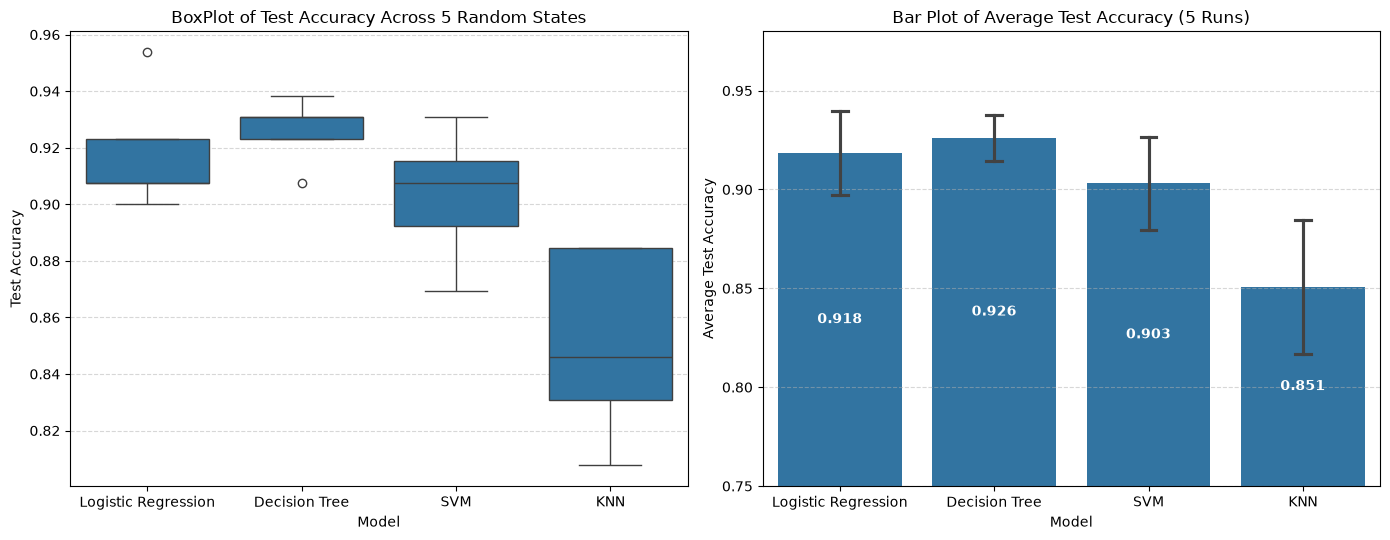

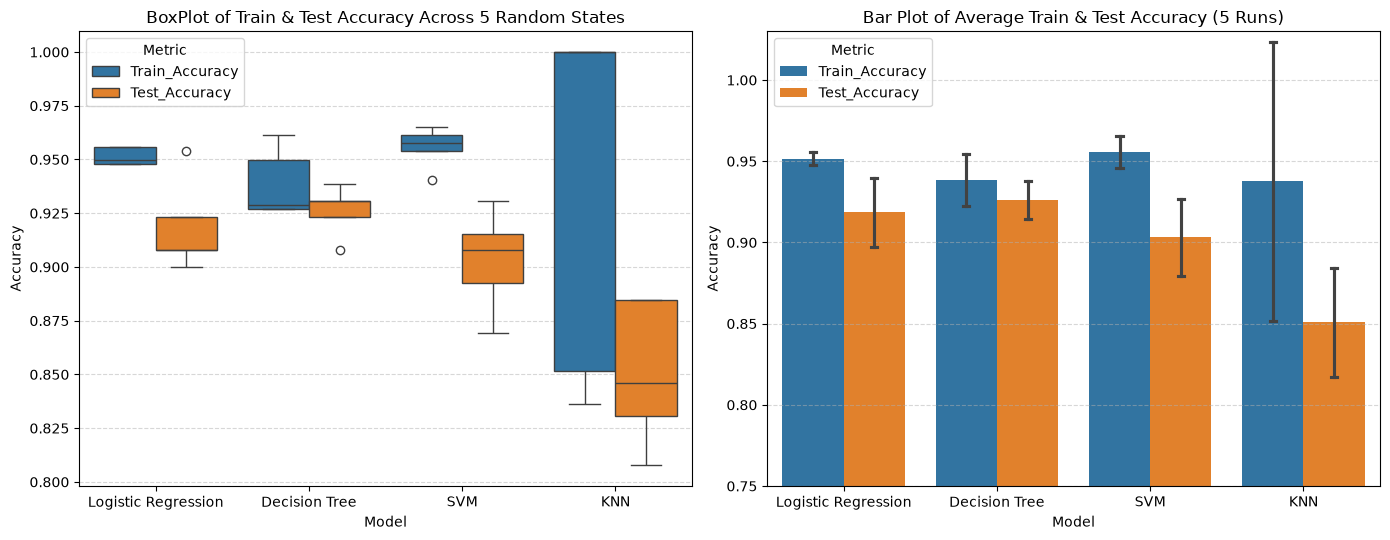

In [38]:
# 8) Change the random_state in task 2.1 and re-calculate all the previous steps. Are your conclusions about
# the best model the same? Make conclusions averaging the performance results for to five different
# random states. Construct the BoxPlots for each ML method and for each of the performance metrics,
# corresponding to the five different runs. Construct the Bar Plots for each ML method and for each of
# the performance metrics with average performance results. Describe and interpret the results.

# 8) Re-calculate previous steps across 5 different random_state values
random_states = [5, 15, 25, 35, 42]
run_records = []

for rs in random_states:
    # Split and scale data for the current random_state
    X_tr, X_te, Y_tr, Y_te = train_test_split(
        X_encoded, Y_encoded, test_size=0.2, random_state=rs
    )
    scaler = MinMaxScaler()
    X_tr_sc = scaler.fit_transform(X_tr)
    X_te_sc = scaler.transform(X_te)
    
    base_models = {
        'Logistic Regression': LogisticRegression(max_iter=1000),
        'Decision Tree': DecisionTreeClassifier(random_state=rs),
        'SVM': SVC(),
        'KNN': KNeighborsClassifier()
    }
    
    # Tune hyperparameters and record test accuracy for each model
    for name, model in base_models.items():
        grid = GridSearchCV(estimator=model, param_grid=param_grids[name], cv=5, scoring='accuracy')
        grid.fit(X_tr_sc, Y_tr)
        best_m = grid.best_estimator_
        
        run_records.append({
            'Random_State': rs,
            'Model': name,
            'Train_Accuracy': accuracy_score(Y_tr, best_m.predict(X_tr_sc)),
            'Test_Accuracy': accuracy_score(Y_te, best_m.predict(X_te_sc))
        })

runs_df = pd.DataFrame(run_records)
pivot_test = runs_df.pivot(index='Random_State', columns='Model', values='Test_Accuracy')
display(pivot_test)

# Display average performance summary
summary_stats = pivot_test.agg(['count', 'mean', 'median', 'min', 'max', 'std']).T
display(summary_stats)

# Construct BoxPlots and Bar Plots for the 5 runs
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
model_order = ['Logistic Regression', 'Decision Tree', 'SVM', 'KNN']

sns.boxplot(data=runs_df, x='Model', y='Test_Accuracy', order=model_order, ax=axes[0])
axes[0].set_title('BoxPlot of Test Accuracy Across 5 Random States')
axes[0].set_ylabel('Test Accuracy')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

sns.barplot(data=runs_df, x='Model', y='Test_Accuracy', order=model_order, errorbar='sd', capsize=0.1, ax=axes[1])
axes[1].set_title('Bar Plot of Average Test Accuracy (5 Runs)')
axes[1].set_ylabel('Average Test Accuracy')
axes[1].set_ylim(0.75, 0.98)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

#----------------------------------------------------------
axes[1].bar_label(
    axes[1].containers[0], fmt='%.3f', label_type='center',
    color='white', fontsize=10, fontweight='bold'
)
#----------------------------------------------------------


plt.tight_layout()
plt.show()

runs_melted = runs_df.melt(
    id_vars=['Random_State', 'Model'],
    value_vars=['Train_Accuracy', 'Test_Accuracy'],
    var_name='Metric',
    value_name='Accuracy'
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
model_order = ['Logistic Regression', 'Decision Tree', 'SVM', 'KNN']

sns.boxplot(data=runs_melted, x='Model', y='Accuracy', hue='Metric', order=model_order, ax=axes[0])
axes[0].set_title('BoxPlot of Train & Test Accuracy Across 5 Random States')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

sns.barplot(data=runs_melted, x='Model', y='Accuracy', hue='Metric', order=model_order, errorbar='sd', capsize=0.08, ax=axes[1])
axes[1].set_title('Bar Plot of Average Train & Test Accuracy (5 Runs)')
axes[1].set_ylim(0.75, 1.03)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()



In [26]:
# Changing the random seed shifts the winning model: although SVM ranked first on the single 
# split in the earlier step, averaging across multiple random states reveals that the tuned 
# Decision Tree achieves the highest mean test accuracy and the lowest variance. Logistic Regression 
# ranks a close second and reaches the highest individual run score, SVM places third due to a dip on 
# one split, and KNN consistently trails with the lowest average accuracy and widest spread.

# Task 3: Kfold cross validation

In [27]:
# 1) Use the functions Kfold to split your data into 5 disjoint datasets. Output the indexes of the observations
# in each splited dataset.

from sklearn.model_selection import KFold

# Initialize 5-fold cross-validator with shuffling for balanced splits
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Loop through the 5 splits and output the observation indexes for each disjoint dataset
for fold, (train_idx, test_idx) in enumerate(kf.split(X_encoded), start=1):
    print(f"=== Disjoint Dataset {fold} (Size: {len(test_idx)}) ===")
    print("Observation Indexes:", test_idx)
    print()


=== Disjoint Dataset 1 (Size: 130) ===
Observation Indexes: [  2   6  10  24  30  31  39  41  44  49  54  55  56  60  63  65  69  70
  72  76  77  78  81  82  86  90 101 108 109 110 118 131 132 133 135 145
 148 158 163 165 167 174 176 177 181 204 209 210 212 215 218 220 231 244
 247 249 257 264 265 268 271 277 281 292 298 300 311 318 321 327 333 340
 341 344 346 349 350 352 361 362 364 367 374 375 403 405 420 429 430 437
 444 446 447 448 463 478 479 481 493 496 499 507 514 518 522 533 534 535
 540 549 557 570 578 585 589 593 594 601 602 603 606 607 616 617 618 623
 636 642 644 645]

=== Disjoint Dataset 2 (Size: 130) ===
Observation Indexes: [  0   7   9  11  15  18  22  23  28  29  33  42  43  61  66  68  73  75
  79  83  84  88  89  92  93 104 114 116 117 137 140 144 153 155 178 182
 184 188 192 196 199 203 208 211 213 221 227 228 234 235 236 238 248 250
 256 259 260 274 275 278 284 286 289 290 291 296 299 302 304 305 310 312
 319 320 322 328 329 331 332 334 335 336 353 355 357 369 3

In [28]:
# 2) Build 5 models for each of the ML methods, each time taking one dataset as a testset and joint remaining
# datasets as a training set. Use the best hyper-parameter values for each model found in task 2.

# Prepare containers to store the 5 trained models per method and their accuracy scores
trained_kfold_models = {
    'Logistic Regression': [],
    'Decision Tree': [],
    'SVM': [],
    'KNN': []
}
fold_records = []

# Loop through the 5 disjoint splits generated by KFold
for fold, (train_idx, test_idx) in enumerate(kf.split(X_encoded), start=1):
    # 1. Extract training (4 subsets joined) and testing (1 subset) data for this fold
    X_tr_fold = X_encoded.iloc[train_idx]
    X_te_fold = X_encoded.iloc[test_idx]
    Y_tr_fold = Y_encoded[train_idx]
    Y_te_fold = Y_encoded[test_idx]
    
    # 2. Scale features strictly inside each fold to prevent data leakage
    scaler = MinMaxScaler()
    X_tr_fold_sc = scaler.fit_transform(X_tr_fold)
    X_te_fold_sc = scaler.transform(X_te_fold)
    
    # 3. Initialize the 4 models using the optimal hyperparameters from Task 2.4
    opt_models_fold = {
        'Logistic Regression': LogisticRegression(C=100, max_iter=1000),
        'Decision Tree': DecisionTreeClassifier(max_depth=3, min_samples_split=2, random_state=42),
        'SVM': SVC(C=100, kernel='linear'),
        'KNN': KNeighborsClassifier(n_neighbors=11, weights='distance')
    }
    
    # 4. Fit each model on the current fold's training set and save the results
    for name, model in opt_models_fold.items():
        model.fit(X_tr_fold_sc, Y_tr_fold)
        trained_kfold_models[name].append(model)
        
        tr_acc = accuracy_score(Y_tr_fold, model.predict(X_tr_fold_sc))
        te_acc = accuracy_score(Y_te_fold, model.predict(X_te_fold_sc))
        
        fold_records.append({
            'Fold': f"Fold {fold}",
            'Model': name,
            'Train_Accuracy': tr_acc,
            'Test_Accuracy': te_acc
        })

# Verify that 5 models were built for each ML method
for name, model_list in trained_kfold_models.items():
    print(f"{name}: {len(model_list)} models trained")

# Convert records into a DataFrame and preview Training Accuracy across folds
fold_df = pd.DataFrame(fold_records)
pivot_kfold_train = fold_df.pivot(index='Fold', columns='Model', values='Train_Accuracy')
display(pivot_kfold_train)


Logistic Regression: 5 models trained
Decision Tree: 5 models trained
SVM: 5 models trained
KNN: 5 models trained


Model,Decision Tree,KNN,Logistic Regression,SVM
Fold,,,,
Fold 1,0.949904,1.0,0.949904,0.961464
Fold 2,0.930636,1.0,0.963391,0.963391
Fold 3,0.940270,1.0,0.965318,0.969171
Fold 4,0.934489,1.0,0.944123,0.955684
Fold 5,0.951923,1.0,0.961538,0.967308


Test Accuracy for each fold:


Model,Decision Tree,KNN,Logistic Regression,SVM
Fold,,,,
Fold 1,0.907692,0.884615,0.907692,0.915385
Fold 2,0.915385,0.861538,0.946154,0.923077
Fold 3,0.907692,0.784615,0.907692,0.900000
Fold 4,0.915385,0.815385,0.915385,0.907692
Fold 5,0.914729,0.875969,0.922481,0.906977



Average Test Accuracy across the 5 folds:


,mean,std,min,max
Model,,,,
Decision Tree,0.912177,0.004102,0.907692,0.915385
KNN,0.844425,0.042789,0.784615,0.884615
Logistic Regression,0.919881,0.015925,0.907692,0.946154
SVM,0.910626,0.008839,0.900000,0.923077


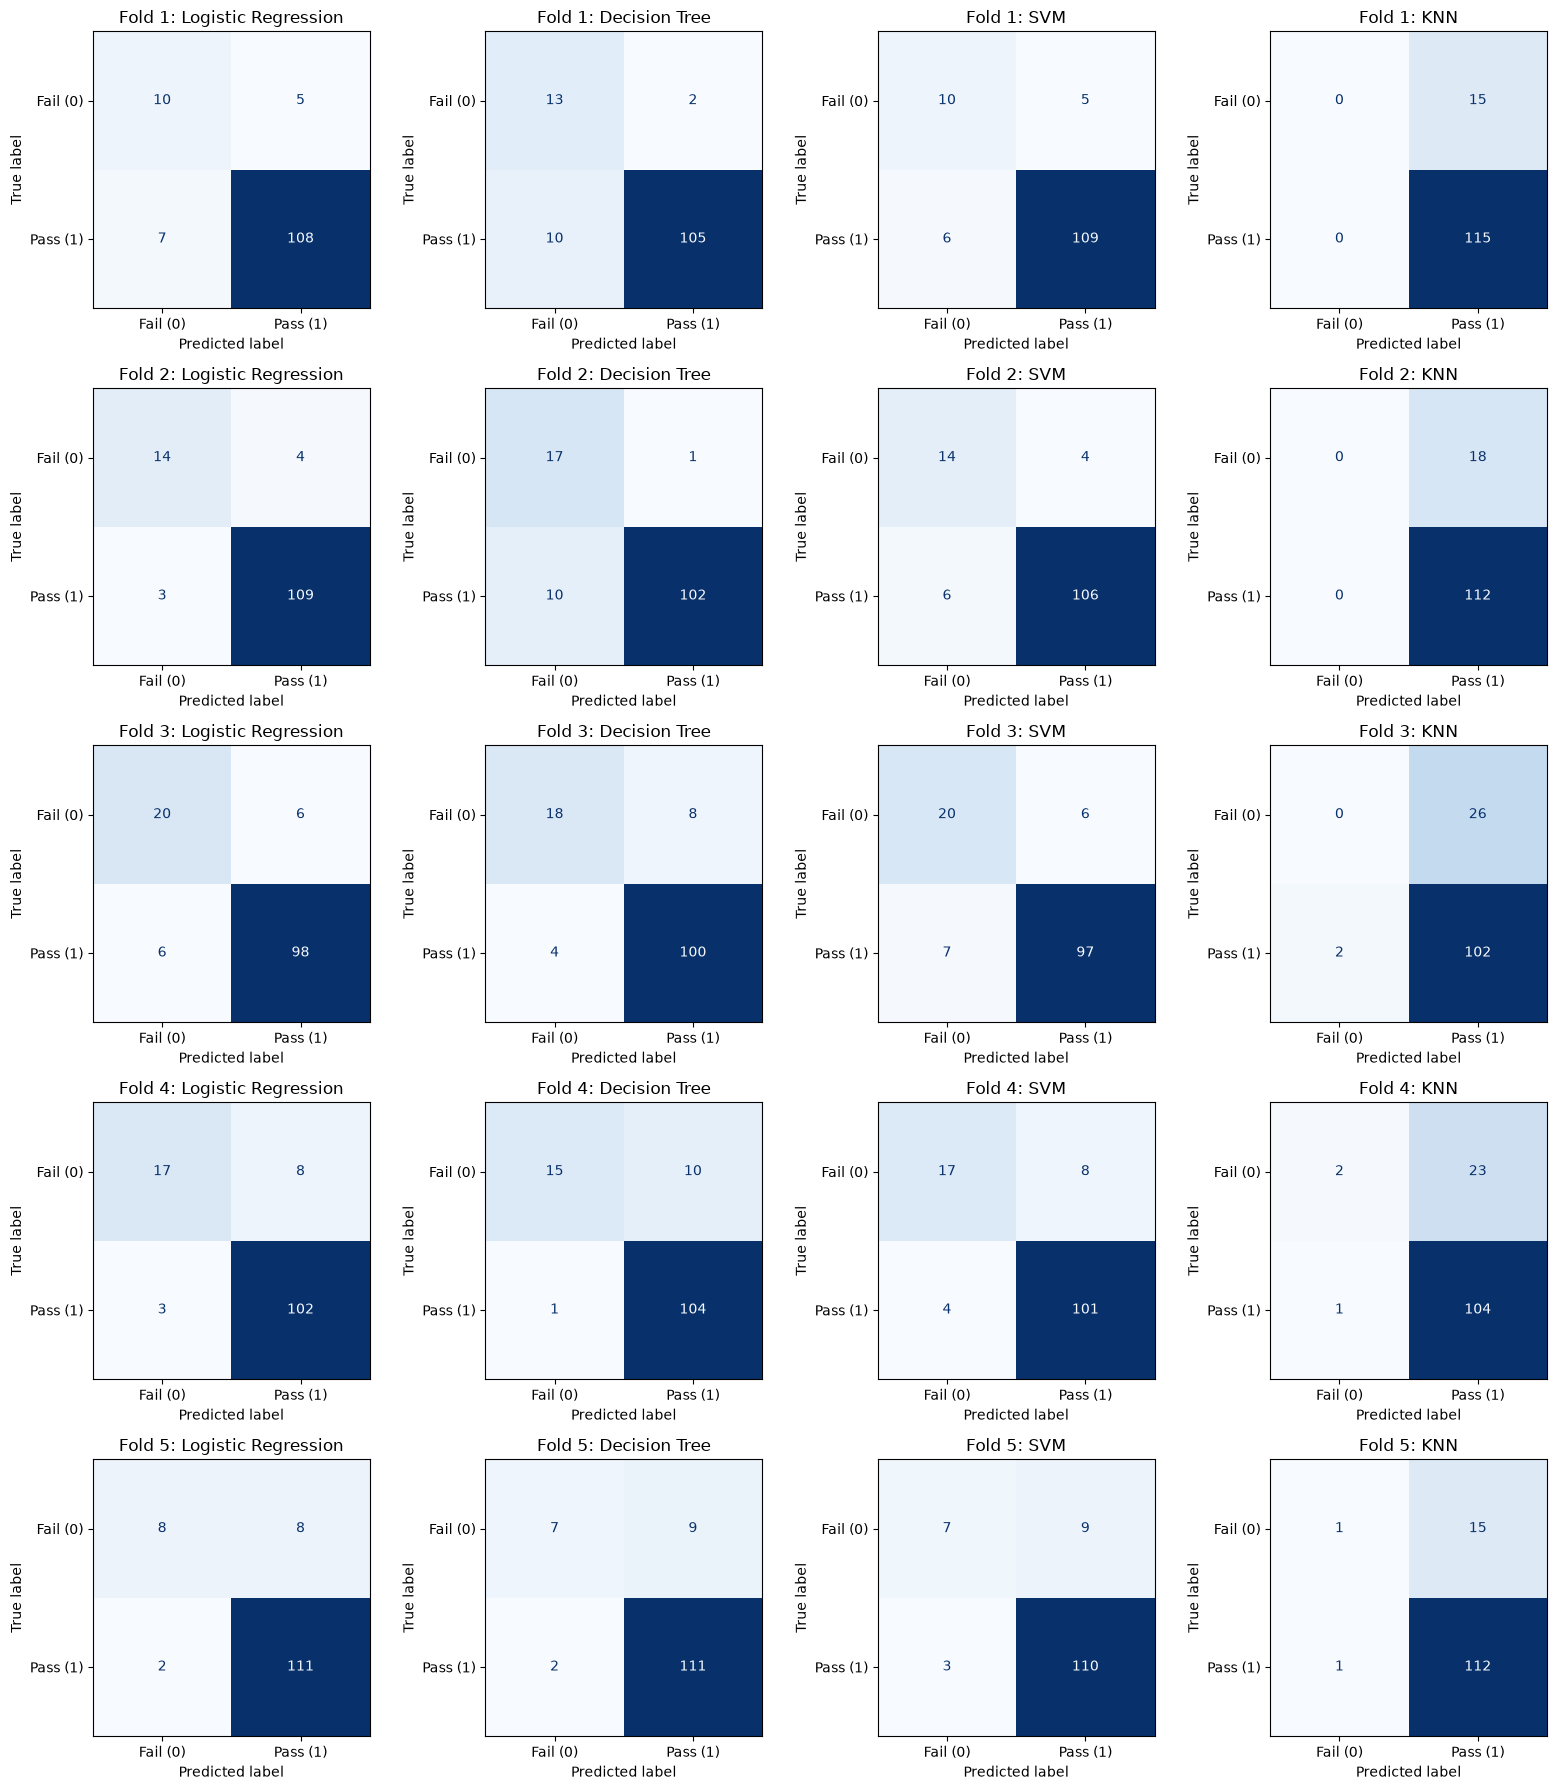

In [29]:
# 3) Evaluate the models’ performance of each fold for each ML method separately on the base of accuracy metric.
# Output the results of each fold and compute an average value of the metric.

# 1. Output the Test Accuracy results of each fold for each ML method
pivot_kfold_test = fold_df.pivot(index='Fold', columns='Model', values='Test_Accuracy')
print("Test Accuracy for each fold:")
display(pivot_kfold_test)

# 2. Compute and output the average value (and summary statistics) of the metric across the 5 folds
kfold_summary = pivot_kfold_test.agg(['count', 'mean', 'median', 'min', 'max', 'std']).T
print("\nAverage Test Accuracy across the 5 folds:")
display(kfold_summary[['mean', 'std', 'min', 'max']])

# 3. Output the Confusion Matrix for each of the folds (5 folds x 4 ML methods)
model_order = ['Logistic Regression', 'Decision Tree', 'SVM', 'KNN']
fig, axes = plt.subplots(5, 4, figsize=(16, 18))

for fold_idx, (train_idx, test_idx) in enumerate(kf.split(X_encoded)):
    scaler = MinMaxScaler()
    scaler.fit(X_encoded.iloc[train_idx])
    X_te_fold_sc = scaler.transform(X_encoded.iloc[test_idx])
    Y_te_fold = Y_encoded[test_idx]
    
    for col_idx, name in enumerate(model_order):
        model = trained_kfold_models[name][fold_idx]
        preds = model.predict(X_te_fold_sc)
        cm = confusion_matrix(Y_te_fold, preds)
        
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Fail (0)', 'Pass (1)'])
        disp.plot(ax=axes[fold_idx, col_idx], cmap='Blues', colorbar=False)
        axes[fold_idx, col_idx].set_title(f"Fold {fold_idx + 1}: {name}")

plt.tight_layout()
plt.show()


In [30]:
# 4) Make conclusions about the best model and corresponding ML method.

# Identify the best ML method (highest average accuracy) and best individual fold model
best_method = kfold_summary['mean'].idxmax()
best_method_score = kfold_summary['mean'].max()

best_single_row = fold_df.loc[fold_df['Test_Accuracy'].idxmax()]
print(f"Best ML Method on average: {best_method} (Mean Test Accuracy: {best_method_score:.4f})")
print(f"Best individual model: {best_single_row['Model']} on {best_single_row['Fold']} (Test Accuracy: {best_single_row['Test_Accuracy']:.4f})")

# Conclusions:
# - Best ML Method: Logistic Regression is the best-performing ML method overall across the 5 folds, 
#   achieving the highest average test accuracy of 91.99% (0.9199), followed closely by the tuned 
#   Decision Tree at 91.22% (0.9122) and SVM at 91.06% (0.9106), while KNN performs the worst at 84.44% (0.8444).
# - Best Individual Model: Out of the 20 trained fold models, the Logistic Regression model trained on Fold 2 
#   achieves the highest single-fold test accuracy of 94.62% (0.9462), while the pruned Decision Tree shows 
#   the highest stability across folds with the lowest standard deviation (0.0041).


Best ML Method on average: Logistic Regression (Mean Test Accuracy: 0.9199)
Best individual model: Logistic Regression on Fold 2 (Test Accuracy: 0.9462)


,Task 2.8 Mean (5 Random Splits),Task 2.8 Std,Task 3 Mean (5-Fold CV),Task 3 Std
Model,,,,
Logistic Regression,0.918462,0.021483,0.919881,0.015925
Decision Tree,0.926154,0.011666,0.912177,0.004102
SVM,0.903077,0.023458,0.910626,0.008839
KNN,0.850769,0.033794,0.844425,0.042789


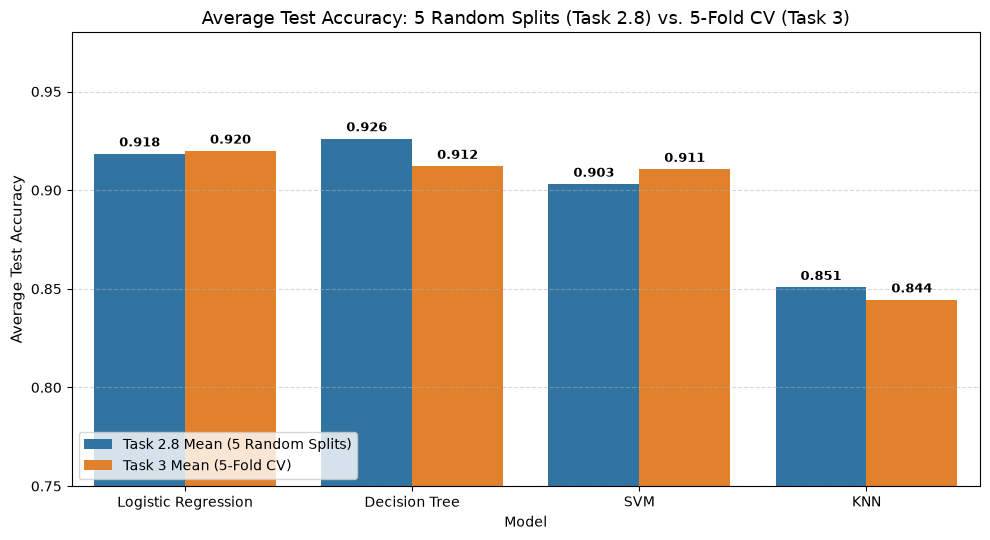

In [39]:
# 5) Construct the Bar Plots for each ML method and for each of the performance metrics with average
# performance results and compare the results with Task 2.8. Make conclusions.

# # 1. Construct the Bar Plot of average Test Accuracy across the 5 folds for each ML method
# fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# sns.barplot(data=fold_df, x='Model', y='Test_Accuracy', order=model_order, errorbar='sd', capsize=0.1, ax=axes[0])
# axes[0].set_title('Task 3.5: Average K-Fold Test Accuracy (5 Folds)')
# axes[0].set_ylabel('Average Test Accuracy')
# axes[0].set_ylim(0.75, 0.98)
# axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# # 2. Compare Task 3 (5-Fold CV) average results with Task 2.8 (5 Random Splits)
# comparison_2_8_vs_3 = pd.DataFrame({
#     'Task 2.8 Mean (5 Random Splits)': summary_stats['mean'],
#     'Task 2.8 Std': summary_stats['std'],
#     'Task 3 Mean (5-Fold CV)': kfold_summary['mean'],
#     'Task 3 Std': kfold_summary['std']
# }).loc[model_order]

# display(comparison_2_8_vs_3)

# # Plot side-by-side comparison of Task 2.8 vs. Task 3
# plot_comp_df = comparison_2_8_vs_3[['Task 2.8 Mean (5 Random Splits)', 'Task 3 Mean (5-Fold CV)']].reset_index()
# plot_comp_df = plot_comp_df.melt(id_vars='Model', var_name='Evaluation Method', value_name='Average Test Accuracy')

# sns.barplot(data=plot_comp_df, x='Model', y='Average Test Accuracy', hue='Evaluation Method', order=model_order, ax=axes[1])
# axes[1].set_title('Comparison of Average Test Accuracy: Task 2.8 vs. Task 3')
# axes[1].set_ylim(0.75, 0.98)
# axes[1].grid(axis='y', linestyle='--', alpha=0.5)
# axes[1].legend(loc='lower left')

# plt.tight_layout()
# plt.show()


#---------------------------------------------------------------------------
# Compare Task 3 (5-Fold CV) average results with Task 2.8 (5 Random Splits)
comparison_2_8_vs_3 = pd.DataFrame({
    'Task 2.8 Mean (5 Random Splits)': summary_stats['mean'],
    'Task 2.8 Std': summary_stats['std'],
    'Task 3 Mean (5-Fold CV)': kfold_summary['mean'],
    'Task 3 Std': kfold_summary['std']
}).loc[model_order]

display(comparison_2_8_vs_3)

# Prepare data for side-by-side comparison bar plot
plot_comp_df = comparison_2_8_vs_3[['Task 2.8 Mean (5 Random Splits)', 'Task 3 Mean (5-Fold CV)']].reset_index()
plot_comp_df = plot_comp_df.melt(id_vars='Model', var_name='Evaluation Method', value_name='Average Test Accuracy')

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(
    data=plot_comp_df,
    x='Model',
    y='Average Test Accuracy',
    hue='Evaluation Method',
    order=model_order,
    ax=ax
)

ax.set_title('Average Test Accuracy: 5 Random Splits (Task 2.8) vs. 5-Fold CV (Task 3)', fontsize=13)
ax.set_ylabel('Average Test Accuracy', fontsize=11)
ax.set_ylim(0.75, 0.98)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend(loc='lower left')

for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3, fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.show()

#---------------------------------------------------------------------------


# Conclusions:
# - In Task 2.8 (5 random splits), Decision Tree ranked first (92.62%) and Logistic Regression ranked second (91.85%), 
#   whereas in Task 3 (5-fold cross-validation), Logistic Regression ranks first (91.99%) and Decision Tree ranks second (91.22%).
# - Both evaluation methods confirm that Logistic Regression, Decision Tree, and SVM (~90.3%–92.6%) strongly outperform KNN (~84.4%–85.1%).
# - 5-Fold Cross-Validation (Task 3) produces much lower standard deviations across folds for Decision Tree (0.0041 vs. 0.0117), 
#   SVM (0.0088 vs. 0.0235), and Logistic Regression (0.0159 vs. 0.0215) than the 5 random splits in Task 2.8, because 
#   disjoint folds guarantee that every student observation is tested exactly once without overlapping test sets.
